<a href="https://colab.research.google.com/github/Gizeh-Gutierrez/Maestria_programacion/blob/main/Pr%C3%A1cticaRegresionDatosCategoricos_271752.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

** Regresión lineal con datos categóricos: Costos, Localidades y Salarios**

📌 Objetivos de la Práctica:
Al finalizar esta práctica, los estudiantes serán capaces de:

- Codificar variables categóricas usando one-hot encoding con K-1 para problemas de regresión
- Realizar AED
- Construir un modelo de regresión con variables dummy
- Interpretar los resultados de los coeficientes
- Analizar los resultados de los errores residuales
- Calcular el desempeño del modelo de regresión.

Problema: Se podría argumentar que el salario está relacionado con el costo de la educación. Por lo tanto, para analizar este argumentos veremos qué sucede cuando usamos las variables independientes cost y location.

# 1. Carga de datos

Carga el conjunto de datos college.csv, que está en campus virtual, en un dataframe. Elige de este conjunto las columnas salary (variable dependiente), cost(variable independiente - numérica) y location (variable independiente categórica).

Realiza lo siguiente:

*   Convierte si es necesario la variable location a tipo de dato categórico
*   Usa la instrucción describe() en las variables salary y cost
* Cuenta la cantidad de datos que hay por categoría en location
* Convierte la variable location usando one-hot encoding



In [1]:
#  Google Drive
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

# Cargar archivo
ruta = "/content/drive/MyDrive/ClassFiles/college.csv"
df = pd.read_csv(ruta)

# Seleccionar únicamente las variables necesarias
df = df[['salary', 'cost', 'location']]

# Verificar estructura
print(df.head())
print(df.info())

Mounted at /content/drive
   salary    cost location
0  119000  189300       NE
1  121000  189600       NE
2  123000  188400       NE
3  123000  188700       NE
4  110000  194200       NE
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85 entries, 0 to 84
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   salary    85 non-null     int64 
 1   cost      85 non-null     int64 
 2   location  85 non-null     object
dtypes: int64(2), object(1)
memory usage: 2.1+ KB
None


In [2]:
#convertir location a categorica

df['location'] = df['location'].astype('category')

print(df.dtypes)

salary         int64
cost           int64
location    category
dtype: object


In [3]:

#instruccion describe en salary
print(df[['salary','cost']].describe())


              salary           cost
count      85.000000      85.000000
mean    95898.823529  142434.470588
std     11937.121912   53913.064578
min     74900.000000   18260.000000
25%     87100.000000   84670.000000
50%     93200.000000  169200.000000
75%    105000.000000  188700.000000
max    123000.000000  227300.000000


In [4]:

# Cantidad de datos por categoria en location
print(df['location'].value_counts())

location
NE    25
W     21
S     20
MW    19
Name: count, dtype: int64


In [7]:

df_dummies = pd.get_dummies(
    df,
    columns=['location'],
    drop_first=True,
    dtype=int
)

print(df_dummies.head())


   salary    cost  location_NE  location_S  location_W
0  119000  189300            1           0           0
1  121000  189600            1           0           0
2  123000  188400            1           0           0
3  123000  188700            1           0           0
4  110000  194200            1           0           0


# 2. Análisis Exploratorio de los Datos

Realiza un análisis exploratorio de los datos y discute lo que observas en cada gráfica.


*   Crea un histograma de la columna salary. Discute lo que observas
* Crea un diagrama de dispersión de salary vs cost, considerando lo siguiente: para cada punto elegirás un color que represente la localidad en la que está el salario y el costo de la educación. Por lo tanto el diagrama de dispersión debería tener puntos en 4 colores distintos. Discute lo que observas
* Emplea un boxplot para saber si hay diferencias en los costos según la ubicación, es decir, con boxplot deberás analizar la distribución de cost por localidad. Discute lo que observas




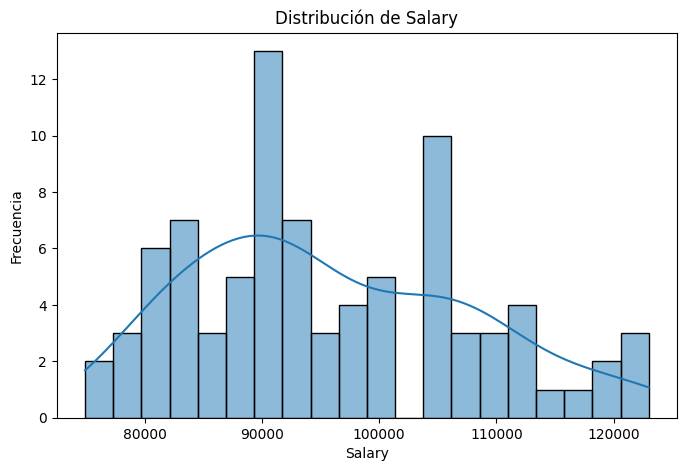

In [8]:
#histograma de Salary
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.histplot(df['salary'], bins=20, kde=True)
plt.title('Distribución de Salary')
plt.xlabel('Salary')
plt.ylabel('Frecuencia')
plt.show()

La mayoría de los salarios se concentran alrededor de 90,000 a 105,000, con un máximo de frecuencia cerca de 90,000. Se observa una ligera tendencia hacia salarios más altos, ya que algunos valores llegan hasta aproximadamente 123,000. En general, los salarios presentan una distribución uniforme, sin valores atípicos extremos ni grupos diferenciados.

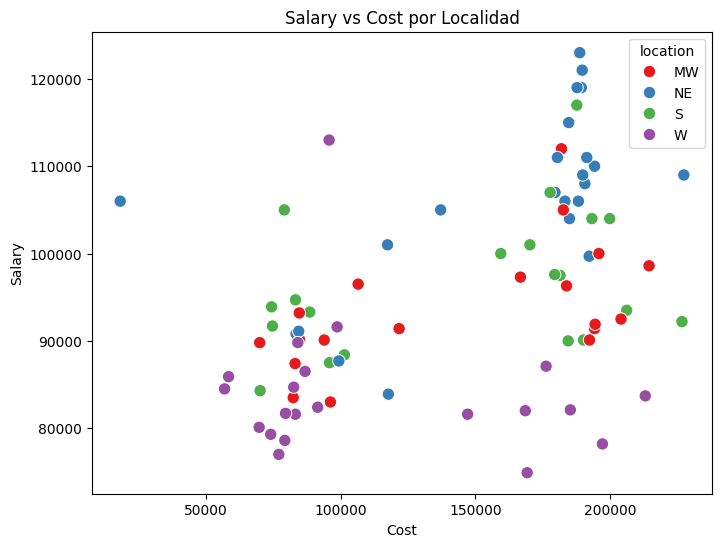

In [9]:
#diagrama de dispersión de salary vs cost
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df,
    x='cost',
    y='salary',
    hue='location',
    palette='Set1',
    s=80
)

plt.title('Salary vs Cost por Localidad')
plt.xlabel('Cost')
plt.ylabel('Salary')
plt.show()

Se puede ver una  relación positiva entre cost y salary, ya que en general los salarios tienden a aumentar cuando el costo de educación es mayor. La región NE concentra varios de los salarios más altos (entre 110,000 y 123,000), mientras que la región W presenta algunos de los salarios más bajos. Aunque existen diferencias entre localidades, hay superposición entre los grupos, por lo que tanto el costo como la ubicación parecen influir en el salario.

/tmp/ipykernel_1826/516000315.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


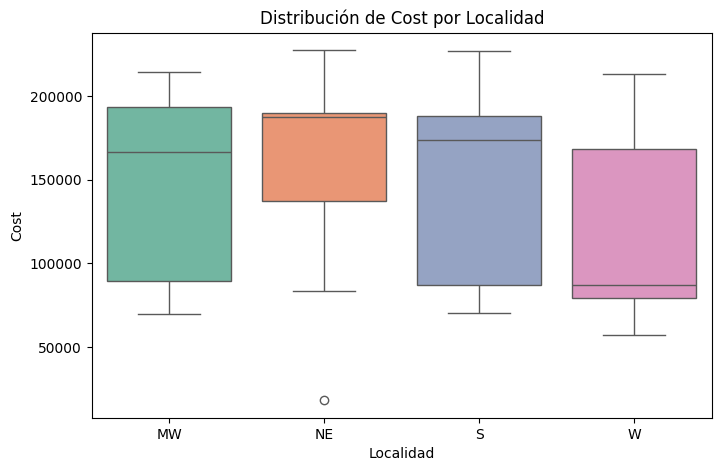

In [10]:
#boxplot de distribución de cost por localidad
plt.figure(figsize=(8,5))
sns.boxplot(
    data=df,
    x='location',
    y='cost',
    palette='Set2'
)

plt.title('Distribución de Cost por Localidad')
plt.xlabel('Localidad')
plt.ylabel('Cost')
plt.show()

La localidad W presenta la mediana de costo más baja, mientras que MW, NE y S tienen medianas considerablemente más altas. Además, NE muestra un valor atípico bajo. En general, los costos de educación son menores en W y más elevados en MW, NE y S, lo que indica diferencias importantes en el costo según la ubicación.

# 3. Construcción del modelo de regresión

- Construye el modelo de regresión usando los datos de salario, costo y location. Recuerda que esta última debe ser en su versión codificada con one-hot encoding.
- Imprime los coeficientes e interpreta qué significan cuando se sustituyen valores en costo, y location (versión codificada). Si no recuerdas cómo se hace esta interpretación consulta los videos.


In [12]:
from sklearn.linear_model import LinearRegression

# X = variables independientes (cost + dummies de location)
X = df_dummies.drop(columns=['salary'])

# y = variable dependiente
y = df_dummies['salary']

# Entrenar modelo
modelo = LinearRegression()
modelo.fit(X, y)

# Coeficientes
coeficientes = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente': modelo.coef_
})

print("Intercepto:", modelo.intercept_)
print(coeficientes)

Intercepto: 84988.71622754404
      Variable   Coeficiente
0         cost      0.060518
1  location_NE  12032.819692
2   location_S   2800.345026
3   location_W  -7721.420103


Ecuación del modelo:

Salary=84988.72+0.0605(Cost)+12032.82(Location_NE)+2800.35(Location_S)−7721.42(Location_W)

Cost (0.0605): por cada $1 adicional de costo, el salario aumenta $0.0605.
Location_NE (12032.82): una universidad en NE tiene un salario esperado $12,032.82 mayor que una universidad en MW.
Location_S (2800.35): una universidad en S tiene un salario esperado $2,800.35 mayor que una universidad en MW.
Location_W (-7721.42): una universidad en W tiene un salario menor $7,721.42 que una universidad en MW.

# 4. Análisis de Residuos

- Construyen una visualización de predicciones (salario estimado) vs valores reales (salario real).
- Crea una gráfica de los errores residuales. Discute lo que observas

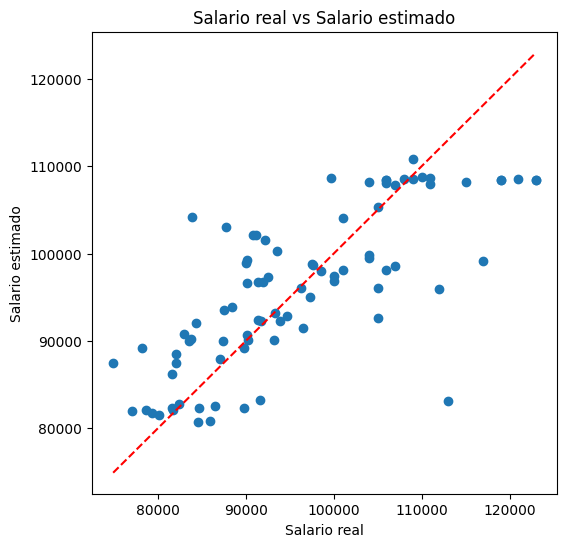

In [14]:
#salario real Vs salario estimado
y_pred = modelo.predict(X)

plt.figure(figsize=(6,6))
plt.scatter(y, y_pred)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
plt.xlabel("Salario real")
plt.ylabel("Salario estimado")
plt.title("Salario real vs Salario estimado")
plt.show()

Los puntos siguen una tendencia diagonal y la mayoría se encuentran cerca de la línea de referencia, lo que indica que el modelo predice bien los salarios. Para salarios reales altos, el modelo tiende a subestimarlos, ya que varias predicciones se concentran alrededor de 108,000. También hay algunos puntos alejados de la línea, lo que muestra errores de predicción en ciertos casos, pero en general el ajuste es bueno.

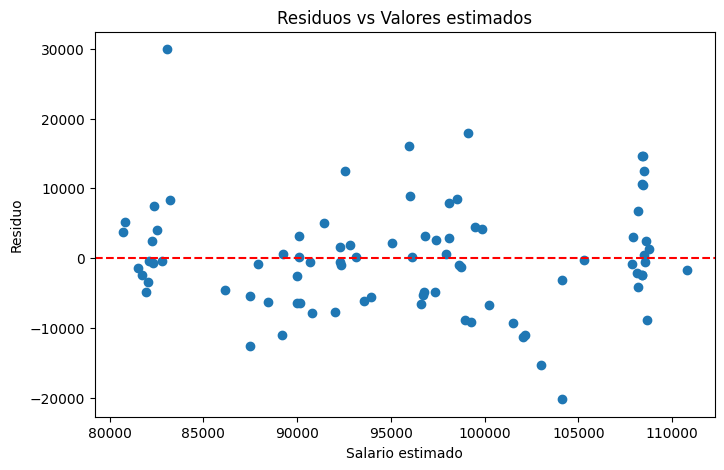

In [15]:
#grafica errores residuales
residuos = y - y_pred

plt.figure(figsize=(8,5))
plt.scatter(y_pred, residuos)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("Salario estimado")
plt.ylabel("Residuo")
plt.title("Residuos vs Valores estimados")
plt.show()

Los residuos están distribuidos alrededor de la línea 0 sin un patrón, lo que indica que el modelo lineal es correcto. La mayoría de los errores se encuentran entre -10,000 y 10,000, aunque hay casos con errores más grandes. No se observa una forma de embudo marcada, la variabilidad de los errores parece constante. En general, el modelo no muestra sesgos relevantes.

# 5. Evalúa el modelo

- Calcula el MSE del modelo construido. Recuerda que usas el propio conjunto de datos (No hablamos nada de entrenamiento y test).
- Calcula el R² Score

Discute estos resultados obtenidos.

In [16]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

print("MSE:", mse)
print("R²:", r2)

MSE: 60480269.14657189
R²: 0.5705089716684086


El modelo obtuvo un R² de 0.57, por lo que explica aproximadamente el 57% de la variación del salario usando las variables cost y location. Aunque estas variables tienen influencia sobre el salario, el MSE elevado indica que existen errores de predicción importantes. En general, el modelo presenta un ajuste moderado y podrían requerirse variables adicionales para mejorar su precisión.

# 6. Realiza un análisis de varianza con stastmodel

Consulta esto aquí https://www.statsmodels.org/dev/examples/notebooks/generated/variance_components.html

In [17]:
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

# Modelo lineal
modelo = smf.ols('salary ~ cost + C(location)', data=df).fit()

# ANOVA
anova = anova_lm(modelo, typ=2)

print(anova)

                   sum_sq    df          F        PR(>F)
C(location)  4.071774e+09   3.0  21.121259  3.570975e-10
cost         7.878166e+08   1.0  12.259774  7.600629e-04
Residual     5.140823e+09  80.0        NaN           NaN


Tanto cost como location influyen significativamente en el salario (p < 0.05). Sin embargo, location tiene un mayor impacto que cost, por lo que la ubicación de la universidad explica mejor las diferencias salariales observadas.